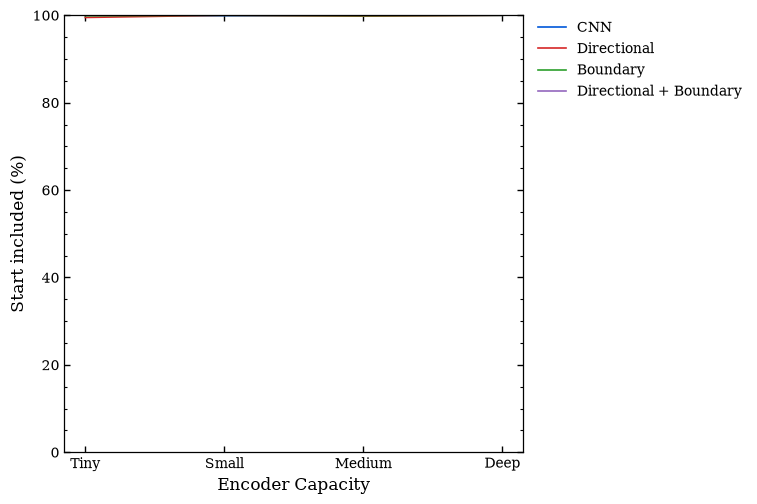

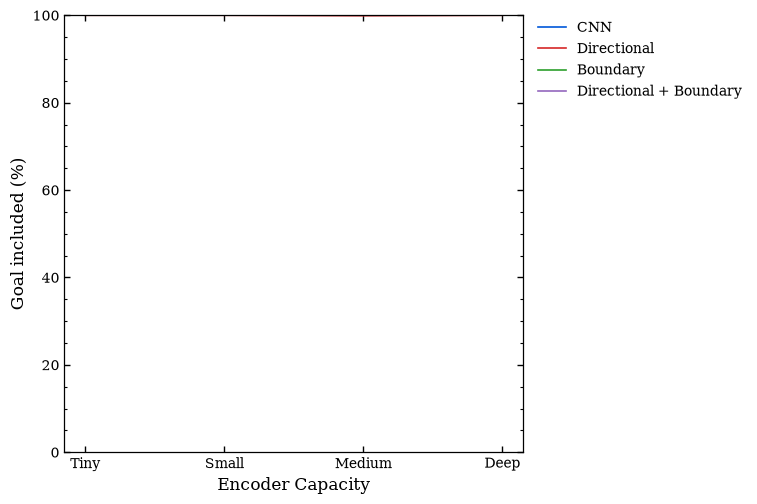

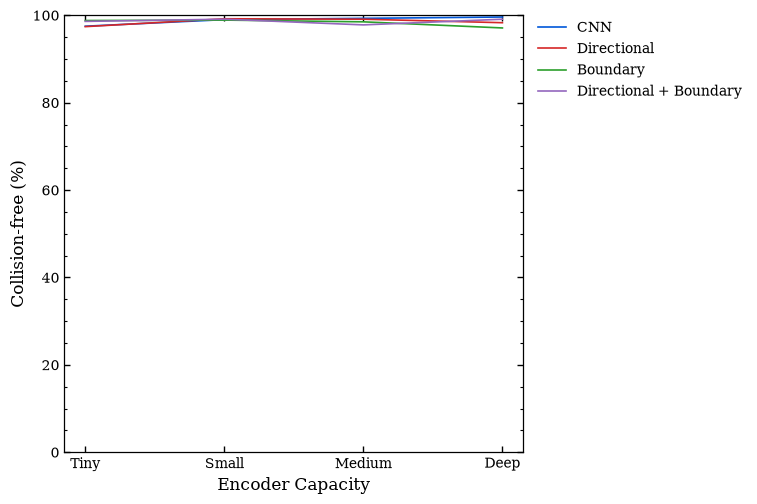

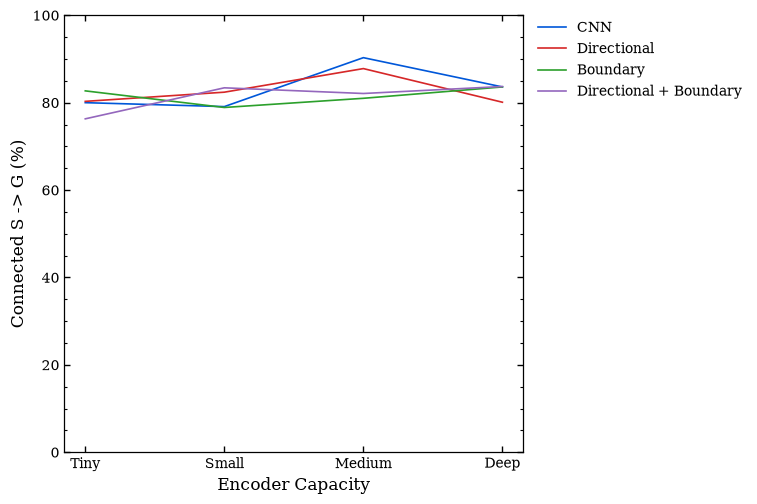

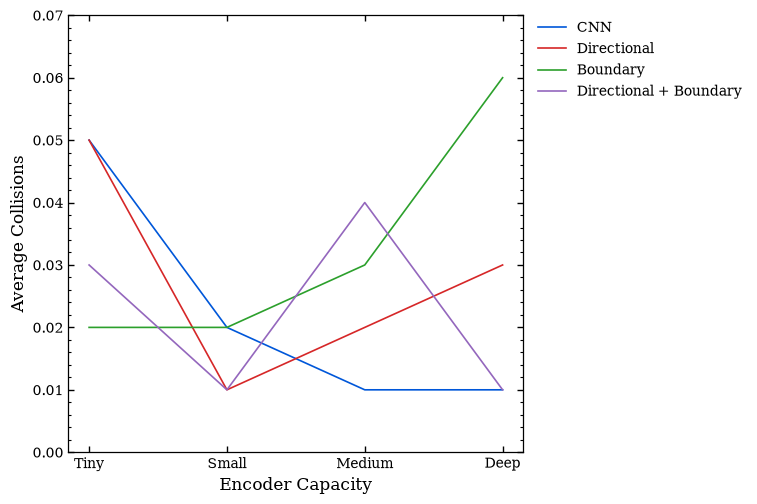

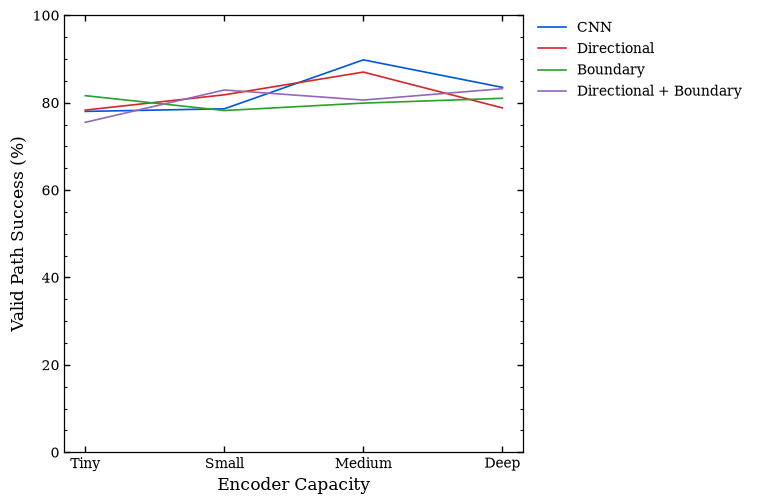

In [5]:
# ============================================================
# Plot one figure per metric
# ============================================================

for metric in metrics:

    # Wider figure
    fig, ax = plt.subplots(figsize=(9.5, 5.2))

    for model_name, model_results in results.items():

        ax.plot(
            x,
            model_results[metric],
            linewidth=1.2,
            # marker="o",          # Use circles for all data points
            markersize=5.5,
            color=styles[model_name]["color"],
            label=model_name,
        )

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------

    ax.set_xlabel("Encoder Capacity")
    ax.set_xticks(x)
    ax.set_xticklabels(sizes)

    if metric == "Average collisions":
        ax.set_ylabel("Average Collisions")

        # Fixed scale for collision count
        ax.set_ylim(0, 0.07)
        ax.set_yticks(np.arange(0, 0.071, 0.01))

    else:
        ax.set_ylabel(f"{metric} (%)")

        # Same Y-axis scale for all percentage metrics
        ax.set_ylim(0, 100)
        ax.set_yticks(np.arange(0, 101, 20))

    # --------------------------------------------------------
    # Minor ticks
    # --------------------------------------------------------

    ax.yaxis.set_minor_locator(AutoMinorLocator())

    ax.tick_params(
        axis="both",
        which="major",
        length=4,
        width=1.0
    )

    ax.tick_params(
        axis="both",
        which="minor",
        length=2,
        width=0.8
    )

    # --------------------------------------------------------
    # Legend outside, upper right
    # --------------------------------------------------------

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0
    )

    # Reserve space for legend
    plt.tight_layout(rect=[0, 0, 0.82, 1])

    plt.show()

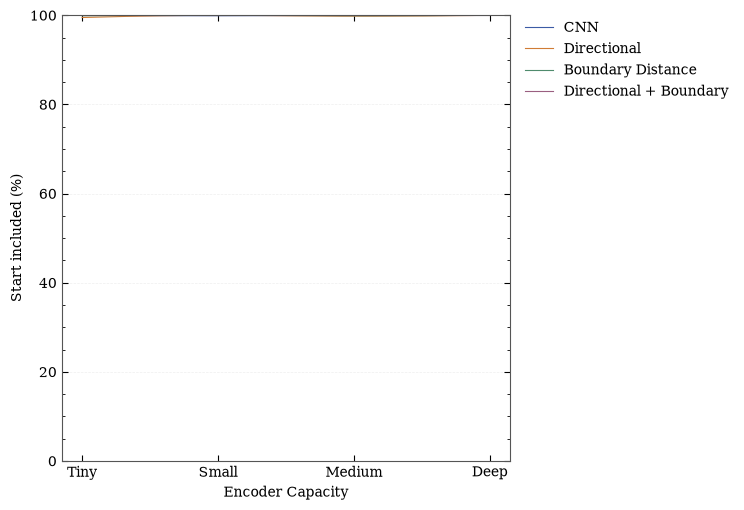

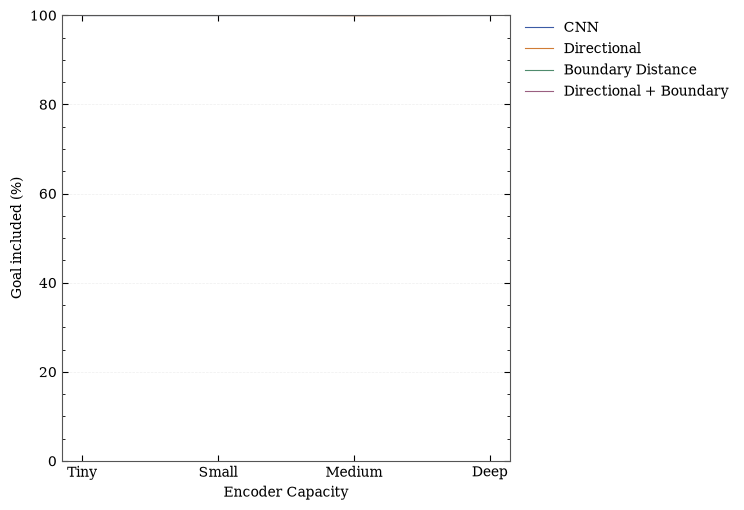

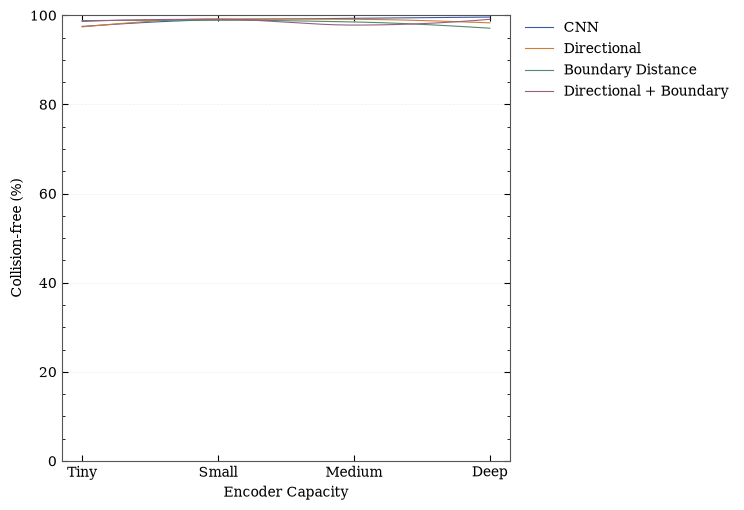

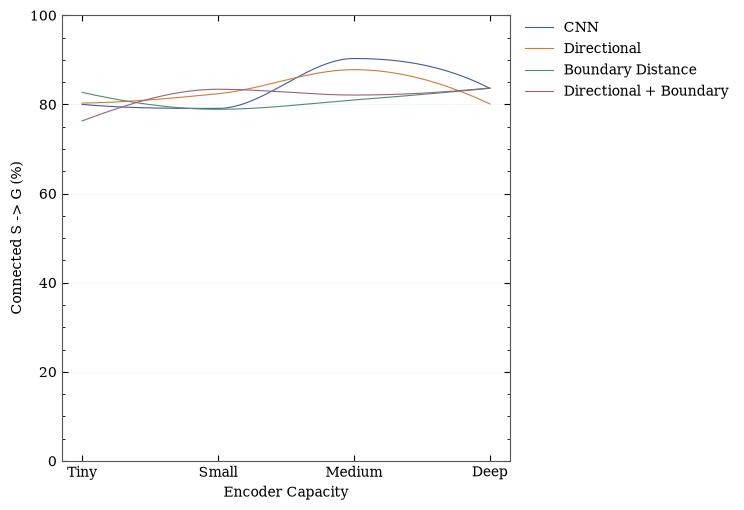

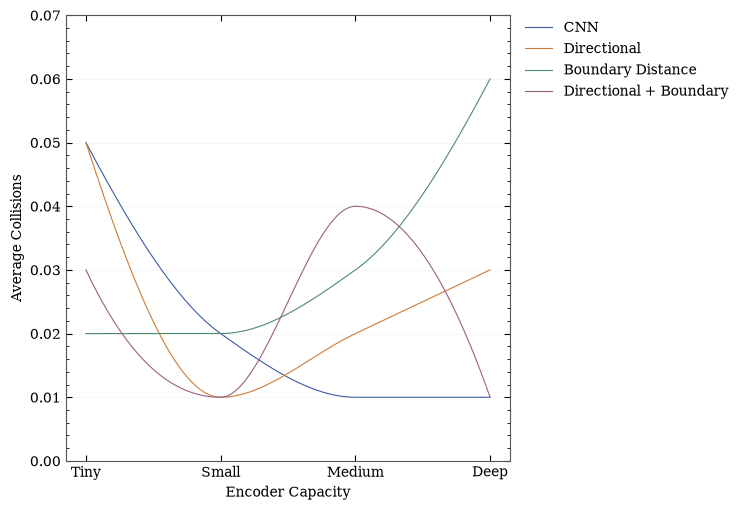

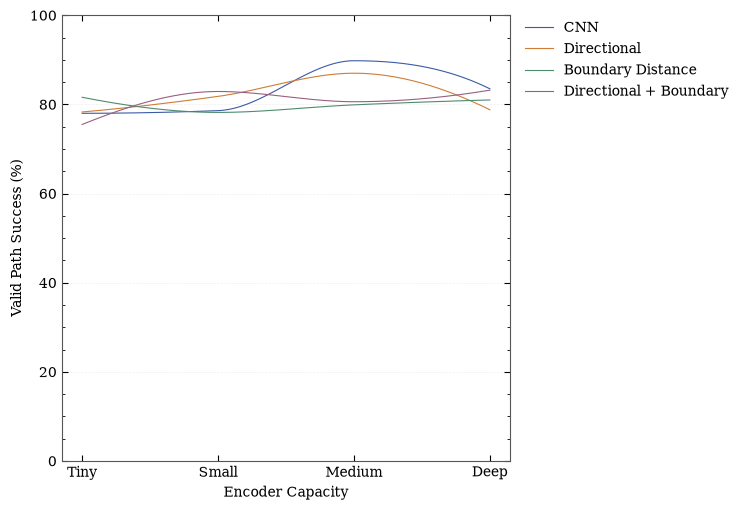

In [22]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.interpolate import PchipInterpolator
from matplotlib.ticker import AutoMinorLocator


# ============================================================
# 1. Experimental results
# ============================================================

sizes = ["Tiny", "Small", "Medium", "Deep"]

results = {

    "CNN": {
        "Start included": [100.0, 99.9, 100.0, 100.0],
        "Goal included": [100.0, 100.0, 100.0, 100.0],
        "Collision-free": [97.5, 99.0, 99.3, 99.6],
        "Connected S -> G": [80.0, 79.1, 90.3, 83.6],
        "Average collisions": [0.05, 0.02, 0.01, 0.01],
        "Valid Path Success": [78.0, 78.6, 89.8, 83.5],
    },

    "Directional": {
        "Start included": [99.5, 100.0, 99.8, 100.0],
        "Goal included": [100.0, 100.0, 99.9, 100.0],
        "Collision-free": [97.4, 99.2, 99.1, 98.3],
        "Connected S -> G": [80.3, 82.4, 87.8, 80.1],
        "Average collisions": [0.05, 0.01, 0.02, 0.03],
        "Valid Path Success": [78.3, 81.8, 87.0, 78.8],
    },

    "Boundary Distance": {
        "Start included": [99.9, 100.0, 99.9, 100.0],
        "Goal included": [100.0, 100.0, 100.0, 100.0],
        "Collision-free": [98.8, 98.9, 98.5, 97.1],
        "Connected S -> G": [82.7, 78.9, 81.0, 83.6],
        "Average collisions": [0.02, 0.02, 0.03, 0.06],
        "Valid Path Success": [81.6, 78.2, 79.9, 81.0],
    },

    "Directional + Boundary": {
        "Start included": [100.0, 100.0, 100.0, 100.0],
        "Goal included": [100.0, 100.0, 100.0, 100.0],
        "Collision-free": [98.6, 99.1, 97.8, 99.1],
        "Connected S -> G": [76.3, 83.4, 82.1, 83.7],
        "Average collisions": [0.03, 0.01, 0.04, 0.01],
        "Valid Path Success": [75.5, 82.9, 80.6, 83.2],
    },
}


# ============================================================
# 2. Metrics to plot
# ============================================================

metrics = [
    "Start included",
    "Goal included",
    "Collision-free",
    "Connected S -> G",
    "Average collisions",
    "Valid Path Success",
]


# ============================================================
# 3. Paper-style colours
# ============================================================

colors = {
    "CNN": "#3B5BA5",                     # muted blue
    "Directional": "#D07C35",             # muted orange
    "Boundary Distance": "#4F8B6D",       # muted green
    "Directional + Boundary": "#9A5F80",  # muted purple
}


# ============================================================
# 4. X-axis
# ============================================================

x = np.arange(len(sizes))

# Dense x coordinates for smooth curves
x_smooth = np.linspace(
    x.min(),
    x.max(),
    300
)


# ============================================================
# 5. Global matplotlib style
# ============================================================

plt.rcParams.update({

    "font.size": 10,

    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "axes.linewidth": 0.5,

    "figure.dpi": 100,
})


# ============================================================
# 6. Plot one figure per metric
# ============================================================

for metric in metrics:

    fig, ax = plt.subplots(
        figsize=(9.5, 5.2)
    )

    # --------------------------------------------------------
    # Plot each encoder
    # --------------------------------------------------------

    for model_name, model_results in results.items():

        y = np.asarray(
            model_results[metric],
            dtype=float
        )

        # Shape-preserving smooth interpolation
        interpolator = PchipInterpolator(
            x,
            y
        )

        y_smooth = interpolator(
            x_smooth
        )

        # Smooth curve only
        ax.plot(
            x_smooth,
            y_smooth,
            linewidth=0.8,
            color=colors[model_name],
            label=model_name,
        )


    # ========================================================
    # X-axis
    # ========================================================

    ax.set_xlabel(
        "Encoder Capacity"
    )

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        sizes
    )


    # ========================================================
    # Y-axis
    # ========================================================

    if metric == "Average collisions":

        ax.set_ylabel(
            "Average Collisions"
        )

        ax.set_ylim(
            0,
            0.07
        )

        ax.set_yticks(
            np.arange(
                0,
                0.071,
                0.01
            )
        )

    else:

        ax.set_ylabel(
            f"{metric} (%)"
        )

        ax.set_ylim(
            0,
            100
        )

        ax.set_yticks(
            np.arange(
                0,
                101,
                20
            )
        )


    # ========================================================
    # Minor ticks
    # ========================================================

    ax.yaxis.set_minor_locator(
        AutoMinorLocator()
    )

    ax.tick_params(
        axis="both",
        which="major",
        length=4,
        width=0.8
    )

    ax.tick_params(
        axis="both",
        which="minor",
        length=2,
        width=0.6
    )


    # ========================================================
    # Paper-style frame
    # ========================================================

    # Full rectangular border
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#555555")
        
    # Lighten left and bottom borders
    ax.spines["left"].set_color("#555555")
    ax.spines["bottom"].set_color("#555555")

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)


    # ========================================================
    # Light horizontal grid
    # ========================================================

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.20
    )

    # Keep curves above grid
    ax.set_axisbelow(True)


    # ========================================================
    # Legend
    # ========================================================

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0,
        frameon=False,
    )


    # ========================================================
    # Layout
    # ========================================================

    plt.tight_layout(
        rect=[0, 0, 0.80, 1]
    )

    plt.show()

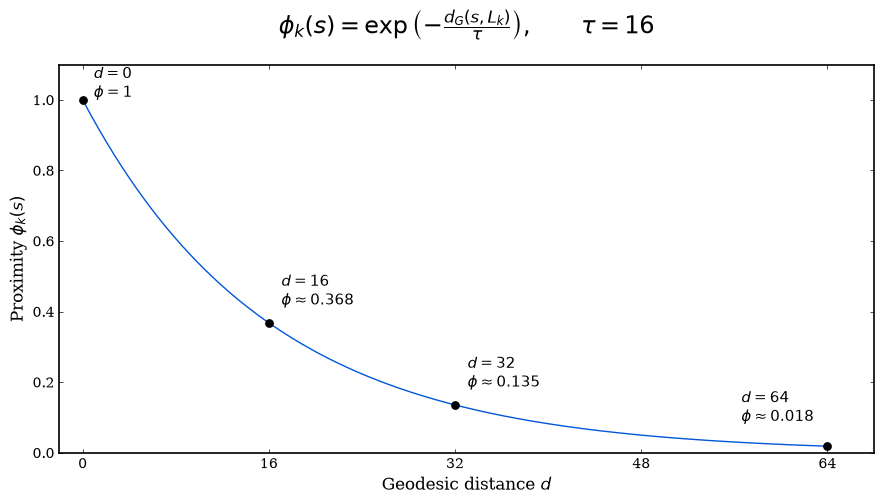

In [4]:
# ============================================================
# Topological Landmark Representation
# Exponential Geodesic Proximity Transform
#
# phi_k(s) = exp(-d_G(s, L_k) / tau)
# tau = 16
#
# Standalone Jupyter code
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

# ------------------------------------------------------------
# Plot style — unchanged
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "figure.dpi": 100,
})

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

LANDMARK_TAU = 16.0

d = np.linspace(0, 64, 500)
phi = np.exp(-d / LANDMARK_TAU)

# Reference distances
d_points = np.array([0, 16, 32, 64])
phi_points = np.exp(-d_points / LANDMARK_TAU)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9.0, 5.2))

ax.plot(
    d,
    phi,
    linewidth=1.0,
    color="#0057D9",
)

# Reference points
ax.scatter(
    d_points,
    phi_points,
    color="black",
    s=28,
    zorder=5,
)

# ------------------------------------------------------------
# Point annotations
# ------------------------------------------------------------

annotations = [
    (0, 1.0, r"$d=0$" + "\n" + r"$\phi=1$", (8, -2)),
    (16, np.exp(-1), r"$d=16$" + "\n" + r"$\phi\approx0.368$", (9, 9)),
    (32, np.exp(-2), r"$d=32$" + "\n" + r"$\phi\approx0.135$", (9, 9)),
    (64, np.exp(-4), r"$d=64$" + "\n" + r"$\phi\approx0.018$", (-62, 14)),
]

for x, y, label, offset in annotations:

    ax.annotate(
        label,
        xy=(x, y),
        xytext=offset,
        textcoords="offset points",
        fontsize=11,
        ha="left",
        va="bottom",
    )

# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_xlabel(r"Geodesic distance $d$")
ax.set_ylabel(r"Proximity $\phi_k(s)$")

ax.set_xlim(-2, 68)
ax.set_ylim(0, 1.10)

ax.set_xticks([0, 16, 32, 48, 64])
ax.set_yticks(np.arange(0, 1.01, 0.2))

ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

ax.tick_params(
    axis="both",
    which="major",
    length=3,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="minor",
    length=0,
    width=0.8,
)

# ------------------------------------------------------------
# Formula above the plot
# ------------------------------------------------------------

ax.set_title(
    r"$\phi_k(s)=\exp\left("
    r"-\frac{d_G(s,L_k)}{\tau}"
    r"\right),\qquad \tau=16$",
    fontsize=17,
    pad=22,
)

# ------------------------------------------------------------
# Layout and save
# ------------------------------------------------------------

plt.tight_layout()

fig.savefig(
    "landmark_exponential_decay.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    "landmark_exponential_decay.pdf",
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

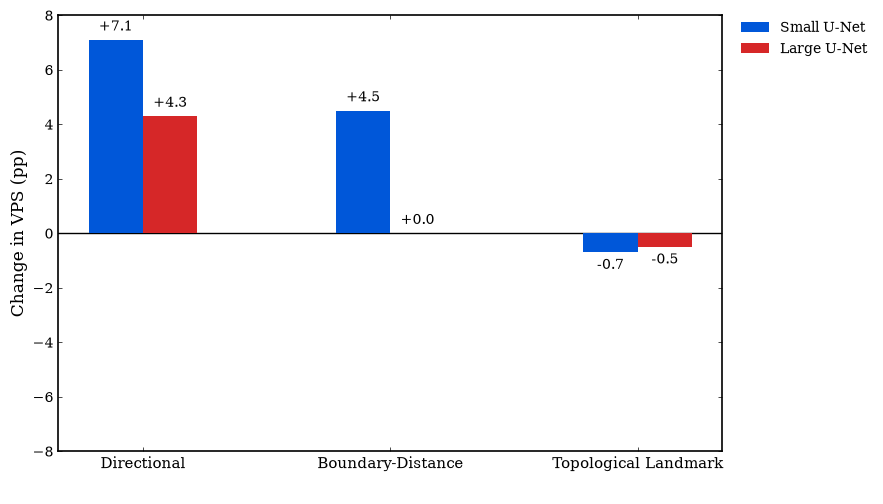

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

# ------------------------------------------------------------
# Plot style
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 11,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "figure.dpi": 100,
})

# ------------------------------------------------------------
# Independent test set: Valid Path Success (%)
# ------------------------------------------------------------
representations = [
    "Directional",
    "Boundary-Distance",
    "Topological Landmark",
]

small_raw = 68.9
large_raw = 79.7

small_vps = np.array([76.0, 73.4, 68.2])
large_vps = np.array([84.0, 79.7, 79.2])

small_delta = small_vps - small_raw
large_delta = large_vps - large_raw

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
x = np.arange(len(representations))
bar_width = 0.22

fig, ax = plt.subplots(figsize=(9.0, 5.2))

bars_small = ax.bar(
    x - bar_width / 2,
    small_delta,
    width=bar_width,
    color="#0057D9",
    label="Small U-Net",
    zorder=3,
)

bars_large = ax.bar(
    x + bar_width / 2,
    large_delta,
    width=bar_width,
    color="#D62728",
    label="Large U-Net",
    zorder=3,
)

# ------------------------------------------------------------
# Value labels
# ------------------------------------------------------------
for bars in (bars_small, bars_large):
    for bar in bars:
        value = bar.get_height()
        offset = 0.22 if value >= 0 else -0.22

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + offset,
            f"{value:+.1f}",
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=10,
        )

# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------
ax.set_xlabel(" ")
ax.set_ylabel("Change in VPS (pp)")

ax.set_xticks(x)
ax.set_xticklabels(representations)

# Zero centred, symmetric Y-axis
ax.set_ylim(-8, 8)

ax.yaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

ax.axhline(
    y=0,
    color="black",
    linewidth=1.0,
    zorder=2,
)

ax.tick_params(
    axis="both",
    which="major",
    length=3,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="minor",
    length=0,
    width=0.8,
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0,
)

# ------------------------------------------------------------
# Layout and export
# ------------------------------------------------------------
plt.tight_layout()

# Vector format recommended for dissertation
fig.savefig(
    "representation_capacity_vps.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "representation_capacity_vps.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


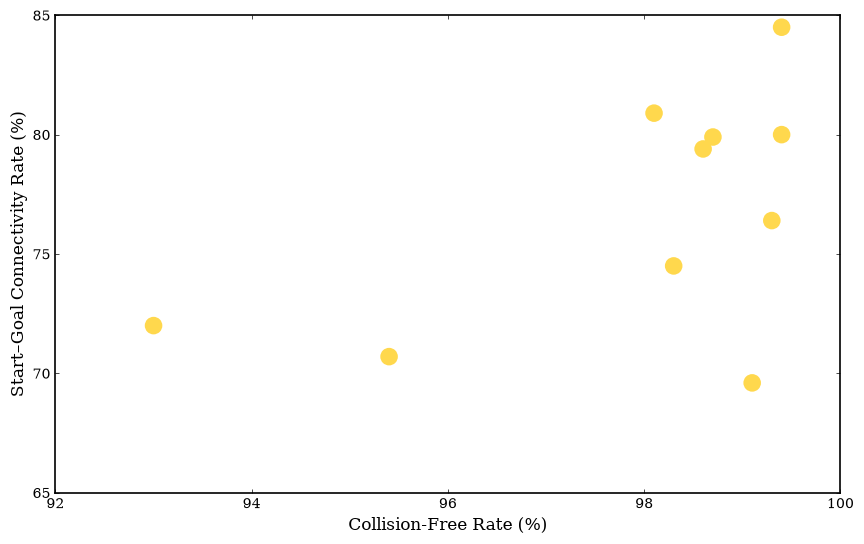

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

# ------------------------------------------------------------
# Plot style
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "figure.dpi": 100,
})

# ------------------------------------------------------------
# Independent test set results
# x = Collision-Free Rate (%)
# y = Start-Goal Connectivity Rate (%)
# ------------------------------------------------------------
labels = [
    "Small Raw",
    "Small Directional",
    "Small Boundary",
    "Small Landmark",
    "Small Noise",
    "Large Raw",
    "Large Directional",
    "Large Boundary",
    "Large Landmark",
    "Large Noise",
]

cf = np.array([
    99.1, 99.3, 98.3, 93.0, 95.4,
    99.4, 99.4, 98.1, 98.7, 98.6
], dtype=float)

conn = np.array([
    69.6, 76.4, 74.5, 72.0, 70.7,
    80.0, 84.5, 80.9, 79.9, 79.4
], dtype=float)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.8, 5.6))

ax.scatter(
    cf,
    conn,
    s=160,
    marker="o",
    color="#FFD84D",     # bright yellow
    edgecolors="none",   # no border
    linewidths=0,
    zorder=3,
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------
ax.set_xlabel("Collision-Free Rate (%)")
ax.set_ylabel("Start–Goal Connectivity Rate (%)")

ax.set_xlim(92, 100)
ax.set_ylim(65, 85)

ax.xaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_major_locator(MultipleLocator(5))

ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

ax.tick_params(
    axis="both",
    which="major",
    length=3,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="minor",
    length=0,
    width=0.8,
)

# ------------------------------------------------------------
# Optional light guide lines
# ------------------------------------------------------------
ax.grid(False)

# ------------------------------------------------------------
# Layout / save
# ------------------------------------------------------------
plt.tight_layout()

fig.savefig(
    "connectivity_vs_collisionfree_scatter.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "connectivity_vs_collisionfree_scatter.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

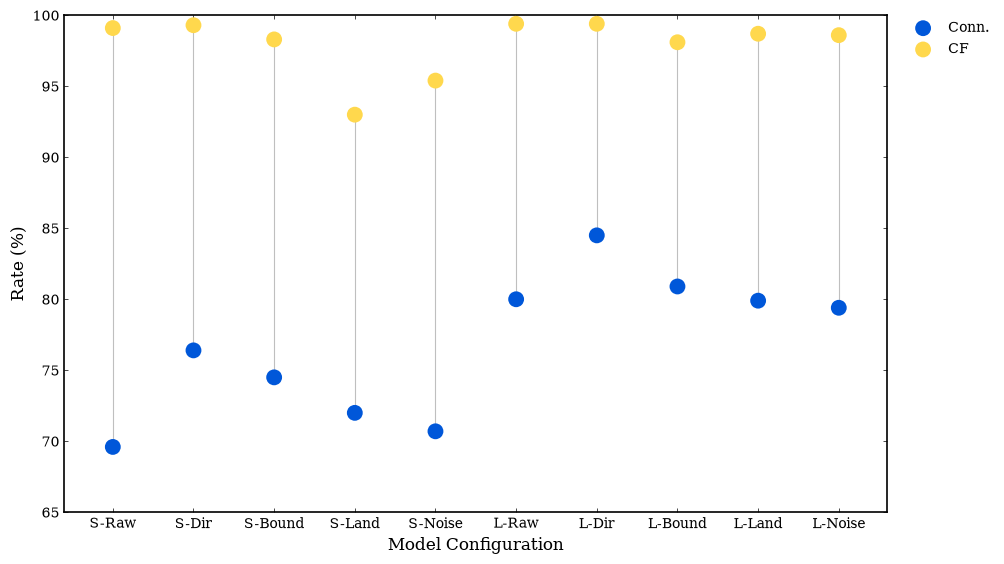

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

# ------------------------------------------------------------
# Plot style
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
    "figure.dpi": 100,
})

# ------------------------------------------------------------
# Independent test set results
# ------------------------------------------------------------
labels = [
    "S-Raw",
    "S-Dir",
    "S-Bound",
    "S-Land",
    "S-Noise",
    "L-Raw",
    "L-Dir",
    "L-Bound",
    "L-Land",
    "L-Noise",
]

cf = np.array([
    99.1, 99.3, 98.3, 93.0, 95.4,
    99.4, 99.4, 98.1, 98.7, 98.6
], dtype=float)

conn = np.array([
    69.6, 76.4, 74.5, 72.0, 70.7,
    80.0, 84.5, 80.9, 79.9, 79.4
], dtype=float)

x = np.arange(len(labels))

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10.2, 5.8))

# thin grey connecting lines
for i in range(len(x)):
    ax.plot(
        [x[i], x[i]],
        [conn[i], cf[i]],
        color="0.75",
        linewidth=0.8,
        zorder=1,
    )

# connectivity points
ax.scatter(
    x,
    conn,
    s=130,
    marker="o",
    color="#0057D9",      # deep blue
    edgecolors="none",
    linewidths=0,
    label="Conn.",
    zorder=3,
)

# collision-free points
ax.scatter(
    x,
    cf,
    s=130,
    marker="o",
    color="#FFD84D",      # bright yellow
    edgecolors="none",
    linewidths=0,
    label="CF",
    zorder=4,
)

# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------
ax.set_xlabel("Model Configuration")
ax.set_ylabel("Rate (%)")

ax.set_xlim(-0.6, len(labels) - 0.4)
ax.set_ylim(65, 100)

ax.set_xticks(x)
ax.set_xticklabels(labels)

ax.yaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_minor_locator(AutoMinorLocator(5))

ax.tick_params(
    axis="both",
    which="major",
    length=3,
    width=0.5,
)

ax.tick_params(
    axis="both",
    which="minor",
    length=0,
    width=0.8,
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------
ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0,
)

# ------------------------------------------------------------
# Layout / save
# ------------------------------------------------------------
plt.tight_layout()

fig.savefig(
    "paired_cf_connectivity_plot.pdf",
    bbox_inches="tight",
)

fig.savefig(
    "paired_cf_connectivity_plot.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()